In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# Veri setini yükle
data = load_breast_cancer()

# DataFrame oluştur
df = pd.DataFrame(data.data, columns=data.feature_names)

# Sınıf etiketlerini ekle
df["target"] = data.target

# Veri seti bilgileri
print("Veri setinin boyutu:", df.shape)
print("\nSınıf isimleri:", data.target_names)
print("\nSınıf dağılımı:")
print(df["target"].value_counts())

# İlk 5 satırı göster
display(df.head())

Veri setinin boyutu: (569, 31)

Sınıf isimleri: ['malignant' 'benign']

Sınıf dağılımı:
target
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:

# Giriş özellikleri ve hedef değişken
X = df.drop("target", axis=1)
y = df["target"]

# Veriyi %80 eğitim, %20 test olarak ayır
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Eğitim verisi:", X_train.shape)
print("Test verisi:", X_test.shape)

print("\nEğitim sınıf dağılımı:")
print(y_train.value_counts())

print("\nTest sınıf dağılımı:")
print(y_test.value_counts())


Eğitim verisi: (455, 30)
Test verisi: (114, 30)

Eğitim sınıf dağılımı:
target
1    285
0    170
Name: count, dtype: int64

Test sınıf dağılımı:
target
1    72
0    42
Name: count, dtype: int64


In [4]:

from sklearn.feature_selection import (
    SelectKBest,
    f_classif,
    mutual_info_classif,
    RFE
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold

# 5 katlı çapraz doğrulama
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Özellik seçimi yöntemleri
feature_methods = {
    "ANOVA": SelectKBest(
        score_func=f_classif,
        k=10
    ),

    "Mutual Information": SelectKBest(
        score_func=lambda X, y: mutual_info_classif(
            X, y, random_state=42
        ),
        k=10
    ),

    "RFE": RFE(
        estimator=LogisticRegression(
            max_iter=5000,
            solver="liblinear"
        ),
        n_features_to_select=10
    )
}

print("Özellik seçimi yöntemleri hazır!")
print("Yöntem sayısı:", len(feature_methods))
print("Çapraz doğrulama:", cv.n_splits, "kat")
print("Seçilecek özellik sayısı: 10")


Özellik seçimi yöntemleri hazır!
Yöntem sayısı: 3
Çapraz doğrulama: 5 kat
Seçilecek özellik sayısı: 10


In [5]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

# Üç farklı sınıflandırma algoritması
classifiers = {
    "k-NN": KNeighborsClassifier(n_neighbors=5),

    "Gaussian Naive Bayes": GaussianNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=5000,
        solver="liblinear",
        random_state=42
    )
}

print("Sınıflandırma algoritmaları hazır!")
print("Algoritma sayısı:", len(classifiers))

for name in classifiers:
    print("-", name)


Sınıflandırma algoritmaları hazır!
Algoritma sayısı: 3
- k-NN
- Gaussian Naive Bayes
- Logistic Regression


In [6]:

from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
import pandas as pd

# Sonuçları saklamak için
cv_results = []

# Üç algoritma için baseline deneyi
for name, model in classifiers.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", clone(model))
    ])

    # 5 katlı çapraz doğrulama
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Ozellik_Secimi": "Baseline",
        "Algoritma": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean()
    })

baseline_df = pd.DataFrame(cv_results)

print("BASELINE - 5 KATLI CAPRAZ DOGRULAMA")
display(baseline_df.round(4))


BASELINE - 5 KATLI CAPRAZ DOGRULAMA


,Ozellik_Secimi,Algoritma,Accuracy,Precision,Recall,F1,ROC_AUC
0,Baseline,k-NN,0.9626,0.9592,0.9825,0.9705,0.9882
1,Baseline,Gaussian Naive Bayes,0.9341,0.9414,0.9544,0.9478,0.9884
2,Baseline,Logistic Regression,0.9802,0.9827,0.9860,0.9842,0.9960


In [7]:

from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Baseline sonuçları cv_results içinde kayıtlı
# Üç özellik seçimi yöntemini değerlendiriyoruz

for method_name, selector in feature_methods.items():

    for classifier_name, model in classifiers.items():

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("selector", clone(selector)),
            ("classifier", clone(model))
        ])

        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring={
                "accuracy": "accuracy",
                "precision": "precision",
                "recall": "recall",
                "f1": "f1",
                "roc_auc": "roc_auc"
            },
            n_jobs=-1,
            error_score="raise"
        )

        cv_results.append({
            "Ozellik_Secimi": method_name,
            "Algoritma": classifier_name,
            "Accuracy": scores["test_accuracy"].mean(),
            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F1": scores["test_f1"].mean(),
            "ROC_AUC": scores["test_roc_auc"].mean()
        })

results_df = pd.DataFrame(cv_results)

print("TUM DENEYLER - 5 KATLI CAPRAZ DOGRULAMA")
display(results_df.round(4))


TUM DENEYLER - 5 KATLI CAPRAZ DOGRULAMA


,Ozellik_Secimi,Algoritma,Accuracy,Precision,Recall,F1,ROC_AUC
0,Baseline,k-NN,0.9626,0.9592,0.9825,0.9705,0.9882
1,Baseline,Gaussian Naive Bayes,0.9341,0.9414,0.9544,0.9478,0.9884
2,Baseline,Logistic Regression,0.9802,0.9827,0.9860,0.9842,0.9960
3,ANOVA,k-NN,0.9429,0.9483,0.9614,0.9547,0.9759
4,ANOVA,Gaussian Naive Bayes,0.9429,0.9575,0.9509,0.9540,0.9818
5,ANOVA,Logistic Regression,0.9473,0.9584,0.9579,0.9579,0.9869
6,Mutual Information,k-NN,0.9429,0.9452,0.9649,0.9548,0.9718
7,Mutual Information,Gaussian Naive Bayes,0.9297,0.9336,0.9579,0.9451,0.9816
8,Mutual Information,Logistic Regression,0.9363,0.9482,0.9509,0.9493,0.9869
9,RFE,k-NN,0.9714,0.9696,0.9860,0.9774,0.9916


In [8]:

from sklearn.metrics import (
    make_scorer,
    recall_score,
    confusion_matrix
)
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

# Kötü huylu sınıfı pozitif: 0
def specificity_score(y_true, y_pred):
    return recall_score(y_true, y_pred, pos_label=1)

# Tüm metrikler
scoring = {
    "Accuracy": "accuracy",
    "Precision": make_scorer(
        recall_score, pos_label=0
    )
}

# Precision tanımını doğru şekilde güncelle
from sklearn.metrics import precision_score, f1_score

scoring = {
    "Accuracy": "accuracy",
    "Precision": make_scorer(
        precision_score, pos_label=0
    ),
    "Sensitivity": make_scorer(
        recall_score, pos_label=0
    ),
    "Specificity": make_scorer(
        specificity_score
    ),
    "F1": make_scorer(
        f1_score, pos_label=0
    ),
    "ROC_AUC": "roc_auc"
}

# Pozitif sınıfı 0 olacak şekilde ROC-AUC
# hesaplaması için hedefi dönüştürüyoruz.
y_train_malignant = (y_train == 0).astype(int)

print("Değerlendirme metrikleri hazır!")
print("Pozitif sınıf: Kötü huylu")
print("Metrik sayısı:", len(scoring))


Değerlendirme metrikleri hazır!
Pozitif sınıf: Kötü huylu
Metrik sayısı: 6


In [9]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, make_scorer
)
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
import pandas as pd

# Kötü huylu = 1, iyi huylu = 0
y_train_malignant = (y_train == 0).astype(int)

# Yeni hedefe göre performans metrikleri
scoring_malignant = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Sensitivity": "recall",
    "Specificity": make_scorer(
        recall_score, pos_label=0
    ),
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

# Yeni sonuç listesi
final_cv_results = []

# Baseline + 3 özellik seçimi yöntemi
all_methods = {"Baseline": None, **feature_methods}

for method_name, selector in all_methods.items():

    for classifier_name, model in classifiers.items():

        steps = [("scaler", StandardScaler())]

        if selector is not None:
            steps.append(("selector", clone(selector)))

        steps.append(("classifier", clone(model)))

        pipeline = Pipeline(steps)

        scores = cross_validate(
            pipeline,
            X_train,
            y_train_malignant,
            cv=cv,
            scoring=scoring_malignant,
            n_jobs=-1,
            error_score="raise"
        )

        final_cv_results.append({
            "Ozellik_Secimi": method_name,
            "Algoritma": classifier_name,
            **{
                metric: scores["test_" + metric].mean()
                for metric in scoring_malignant
            }
        })

final_cv_df = pd.DataFrame(final_cv_results)

print("12 DENEY - TUM PERFORMANS METRIKLERI")
display(final_cv_df.round(4))


12 DENEY - TUM PERFORMANS METRIKLERI


,Ozellik_Secimi,Algoritma,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC
0,Baseline,k-NN,0.9626,0.9707,0.9294,0.9825,0.9490,0.9882
1,Baseline,Gaussian Naive Bayes,0.9341,0.9220,0.9000,0.9544,0.9106,0.9884
2,Baseline,Logistic Regression,0.9802,0.9770,0.9706,0.9860,0.9735,0.9960
3,ANOVA,k-NN,0.9429,0.9338,0.9118,0.9614,0.9225,0.9759
4,ANOVA,Gaussian Naive Bayes,0.9429,0.9203,0.9294,0.9509,0.9244,0.9818
5,ANOVA,Logistic Regression,0.9473,0.9302,0.9294,0.9579,0.9293,0.9869
6,Mutual Information,k-NN,0.9429,0.9407,0.9059,0.9649,0.9223,0.9718
7,Mutual Information,Gaussian Naive Bayes,0.9297,0.9260,0.8824,0.9579,0.9019,0.9816
8,Mutual Information,Logistic Regression,0.9363,0.9181,0.9118,0.9509,0.9142,0.9869
9,RFE,k-NN,0.9714,0.9773,0.9471,0.9860,0.9611,0.9916


In [10]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
import pandas as pd

# Kötü huylu = 1, iyi huylu = 0
y_test_malignant = (y_test == 0).astype(int)

test_results = []
trained_models = {}

all_methods = {"Baseline": None, **feature_methods}

for method_name, selector in all_methods.items():

    for classifier_name, model in classifiers.items():

        steps = [("scaler", StandardScaler())]

        if selector is not None:
            steps.append(("selector", clone(selector)))

        steps.append(("classifier", clone(model)))

        pipeline = Pipeline(steps)

        # Yalnızca eğitim verisiyle öğren
        pipeline.fit(X_train, y_train_malignant)

        # Test verisi üzerinde tahmin
        y_pred = pipeline.predict(X_test)
        y_prob = pipeline.predict_proba(X_test)[:, 1]

        tn, fp, fn, tp = confusion_matrix(
            y_test_malignant, y_pred,
            labels=[0, 1]
        ).ravel()

        test_results.append({
            "Ozellik_Secimi": method_name,
            "Algoritma": classifier_name,
            "Accuracy": accuracy_score(
                y_test_malignant, y_pred
            ),
            "Precision": precision_score(
                y_test_malignant, y_pred
            ),
            "Sensitivity": recall_score(
                y_test_malignant, y_pred
            ),
            "Specificity": tn / (tn + fp),
            "F1": f1_score(
                y_test_malignant, y_pred
            ),
            "ROC_AUC": roc_auc_score(
                y_test_malignant, y_prob
            ),
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp
        })

        trained_models[(method_name, classifier_name)] = pipeline

test_df = pd.DataFrame(test_results)

print("114 TEST ORNEGI - NIHAI SONUCLAR")
display(test_df.round(4))


114 TEST ORNEGI - NIHAI SONUCLAR


,Ozellik_Secimi,Algoritma,Accuracy,Precision,Sensitivity,Specificity,F1,ROC_AUC,TN,FP,FN,TP
0,Baseline,k-NN,0.9561,0.9512,0.9286,0.9722,0.9398,0.9788,70,2,3,39
1,Baseline,Gaussian Naive Bayes,0.9298,0.9048,0.9048,0.9444,0.9048,0.9868,68,4,4,38
2,Baseline,Logistic Regression,0.9825,0.9762,0.9762,0.9861,0.9762,0.9957,71,1,1,41
3,ANOVA,k-NN,0.9561,0.9512,0.9286,0.9722,0.9398,0.9825,70,2,3,39
4,ANOVA,Gaussian Naive Bayes,0.9298,0.8864,0.9286,0.9306,0.9070,0.9851,67,5,3,39
5,ANOVA,Logistic Regression,0.9474,0.9091,0.9524,0.9444,0.9302,0.9917,68,4,2,40
6,Mutual Information,k-NN,0.9561,0.9512,0.9286,0.9722,0.9398,0.9826,70,2,3,39
7,Mutual Information,Gaussian Naive Bayes,0.9386,0.9070,0.9286,0.9444,0.9176,0.9854,68,4,3,39
8,Mutual Information,Logistic Regression,0.9561,0.9302,0.9524,0.9583,0.9412,0.9917,69,3,2,40
9,RFE,k-NN,0.9561,0.9512,0.9286,0.9722,0.9398,0.9866,70,2,3,39


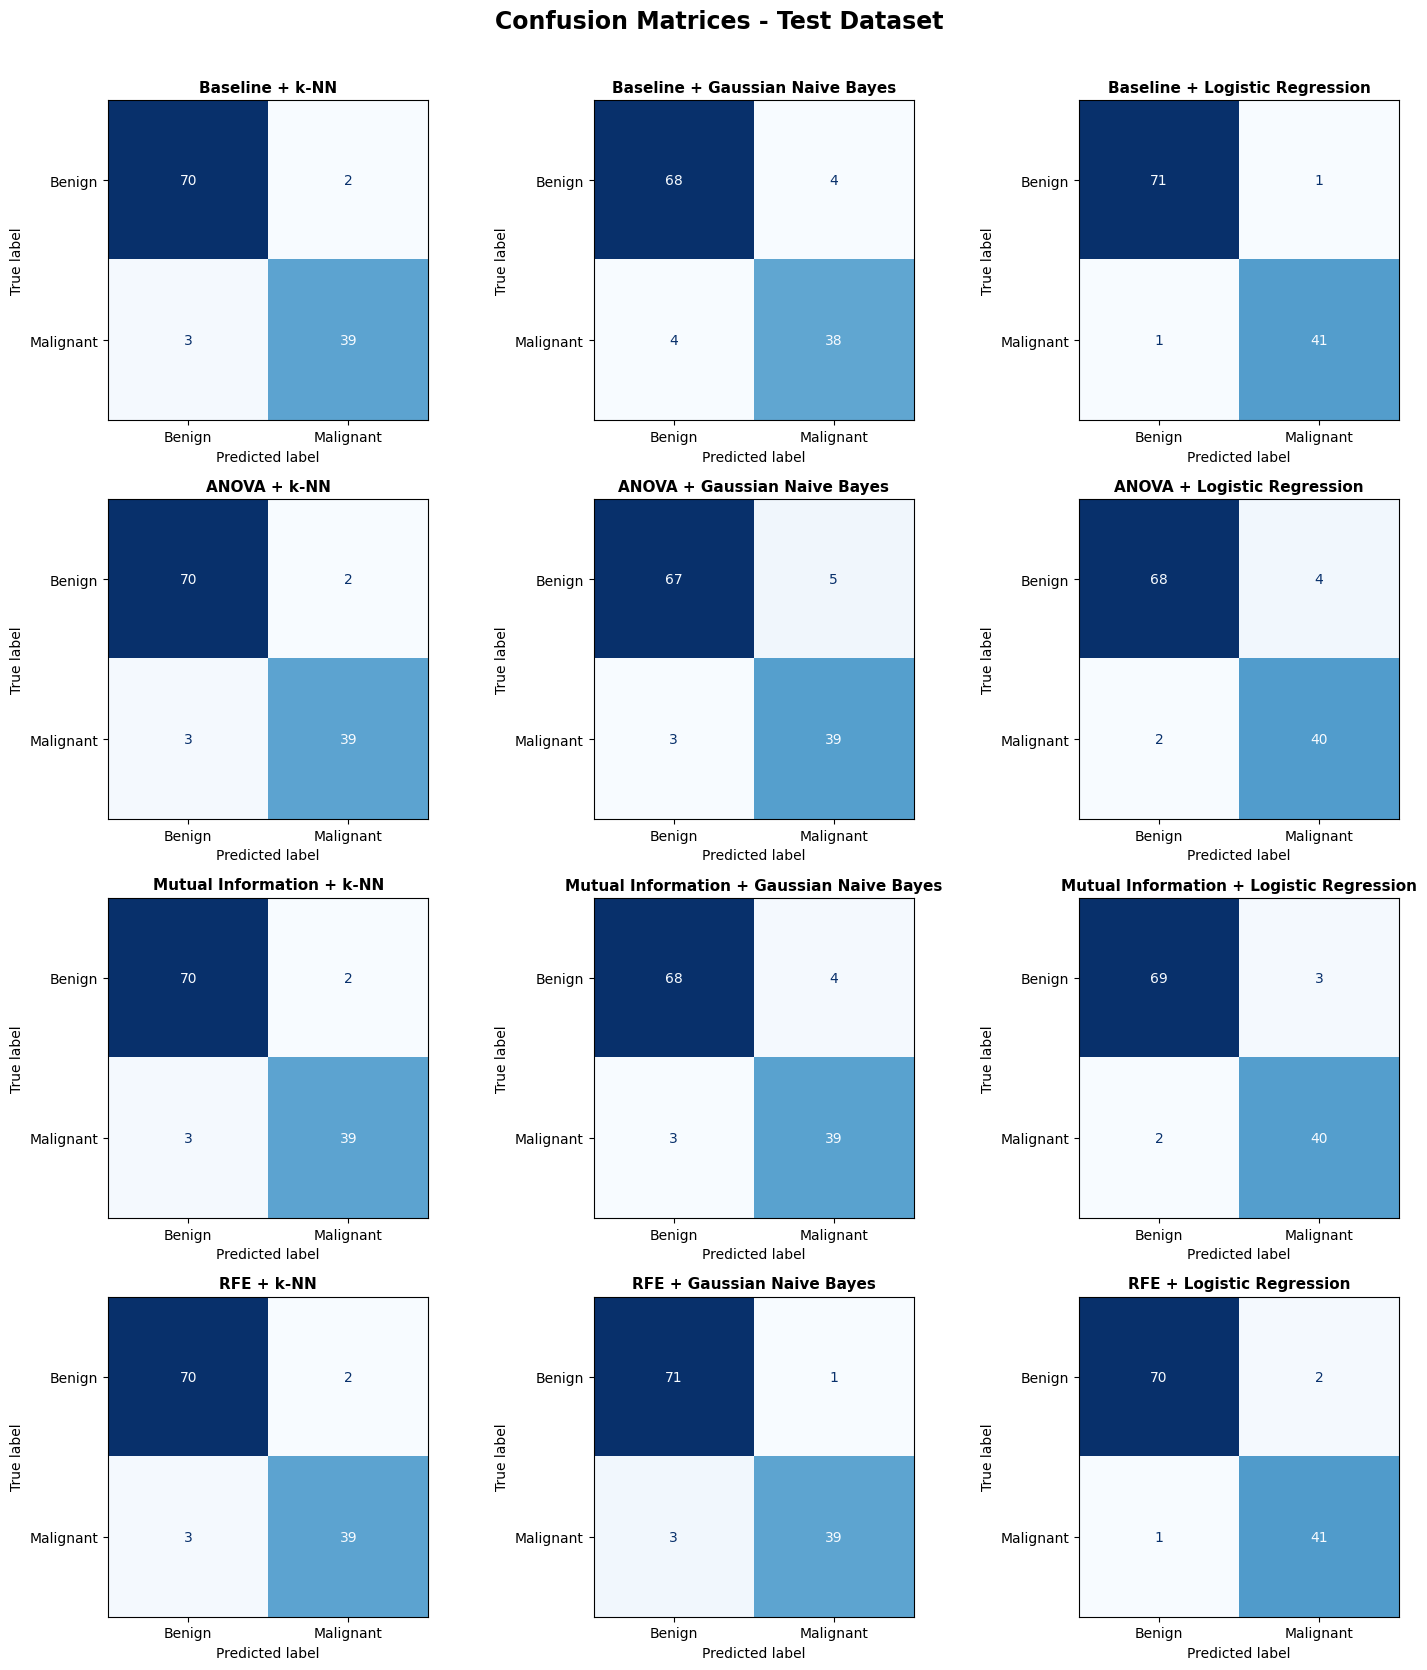

In [11]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

methods = ["Baseline", "ANOVA", "Mutual Information", "RFE"]
algorithm_names = list(classifiers.keys())

fig, axes = plt.subplots(4, 3, figsize=(15, 17))

for i, method in enumerate(methods):
    for j, algorithm in enumerate(algorithm_names):

        model = trained_models[(method, algorithm)]

        y_pred = model.predict(X_test)

        cm = confusion_matrix(
            y_test_malignant,
            y_pred,
            labels=[0, 1]
        )

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Benign", "Malignant"]
        )

        disp.plot(
            ax=axes[i, j],
            cmap="Blues",
            colorbar=False,
            values_format="d"
        )

        axes[i, j].set_title(
            f"{method} + {algorithm}",
            fontsize=11,
            fontweight="bold"
        )

plt.suptitle(
    "Confusion Matrices - Test Dataset",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(
    "confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


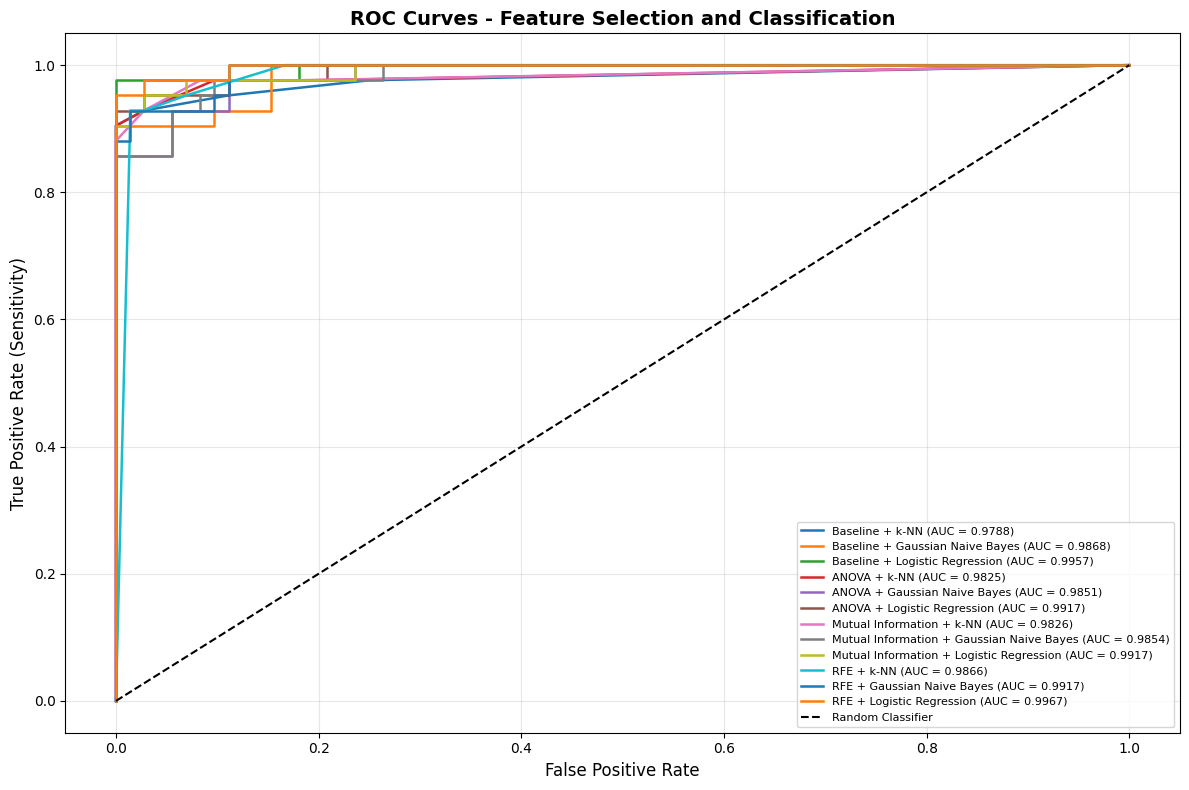

In [12]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(12, 8))

# 12 modelin ROC eğrileri
for (method_name, classifier_name), model in trained_models.items():

    # Kötü huylu sınıfın olasılığı
    y_prob = model.predict_proba(X_test)[:, 1]

    # ROC eğrisi
    fpr, tpr, thresholds = roc_curve(
        y_test_malignant,
        y_prob
    )

    # Eğri altındaki alan
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=1.8,
        label=f"{method_name} + {classifier_name} "
              f"(AUC = {roc_auc:.4f})"
    )

# Rastgele sınıflandırma referansı
plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate (Sensitivity)", fontsize=12)

plt.title(
    "ROC Curves - Feature Selection and Classification",
    fontsize=14,
    fontweight="bold"
)

plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [13]:

import pandas as pd

selected_features = {}

# Her özellik seçimi yönteminin seçtiği değişkenler
for method_name in feature_methods.keys():

    # Daha önce eğitilmiş modelleri kullanıyoruz
    model = trained_models[
        (method_name, "Logistic Regression")
    ]

    # Pipeline içerisindeki özellik seçici
    selector = model.named_steps["selector"]

    # Seçilen özelliklerin indeksleri
    selected_mask = selector.get_support()

    # Özellik isimleri
    features = X_train.columns[selected_mask].tolist()

    selected_features[method_name] = features

    print("\n" + "=" * 45)
    print("YONTEM:", method_name)
    print("SECILEN OZELLIK SAYISI:", len(features))

    for i, feature in enumerate(features, start=1):
        print(f"{i}. {feature}")

# Karşılaştırmalı tablo
features_df = pd.DataFrame(selected_features)

print("\nOZELLIK SECIMI KARSILASTIRMA TABLOSU")
display(features_df)



YONTEM: ANOVA
SECILEN OZELLIK SAYISI: 10
1. mean radius
2. mean perimeter
3. mean area
4. mean concavity
5. mean concave points
6. worst radius
7. worst perimeter
8. worst area
9. worst concavity
10. worst concave points

YONTEM: Mutual Information
SECILEN OZELLIK SAYISI: 10
1. mean radius
2. mean perimeter
3. mean area
4. mean concavity
5. mean concave points
6. area error
7. worst radius
8. worst perimeter
9. worst area
10. worst concave points

YONTEM: RFE
SECILEN OZELLIK SAYISI: 10
1. mean area
2. radius error
3. area error
4. worst radius
5. worst texture
6. worst perimeter
7. worst area
8. worst smoothness
9. worst concavity
10. worst concave points

OZELLIK SECIMI KARSILASTIRMA TABLOSU


,ANOVA,Mutual Information,RFE
0,mean radius,mean radius,mean area
1,mean perimeter,mean perimeter,radius error
2,mean area,mean area,area error
3,mean concavity,mean concavity,worst radius
4,mean concave points,mean concave points,worst texture
5,worst radius,area error,worst perimeter
6,worst perimeter,worst radius,worst area
7,worst area,worst perimeter,worst smoothness
8,worst concavity,worst area,worst concavity
9,worst concave points,worst concave points,worst concave points


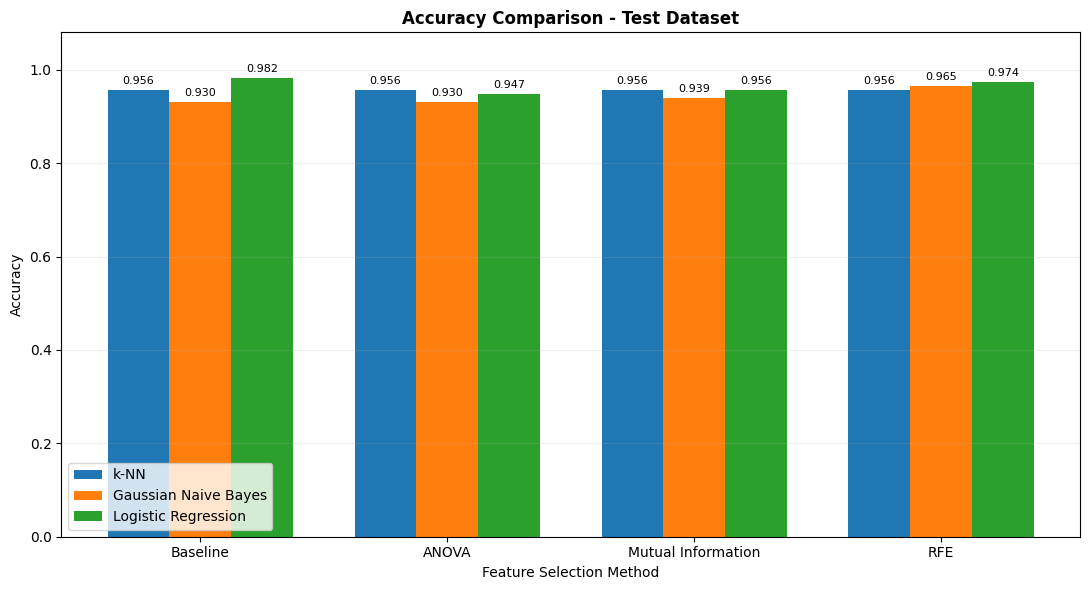

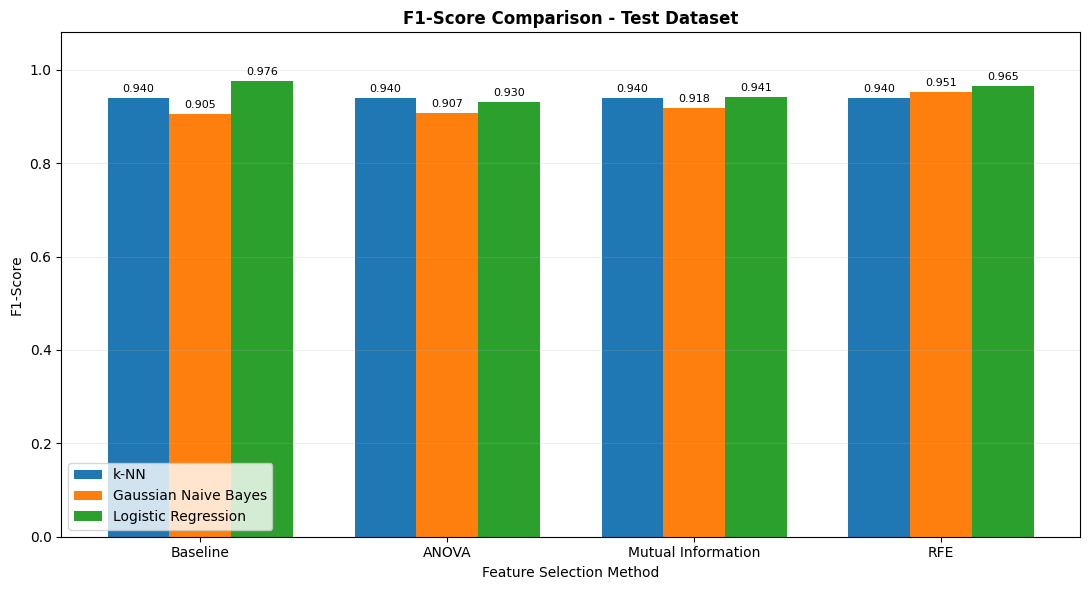

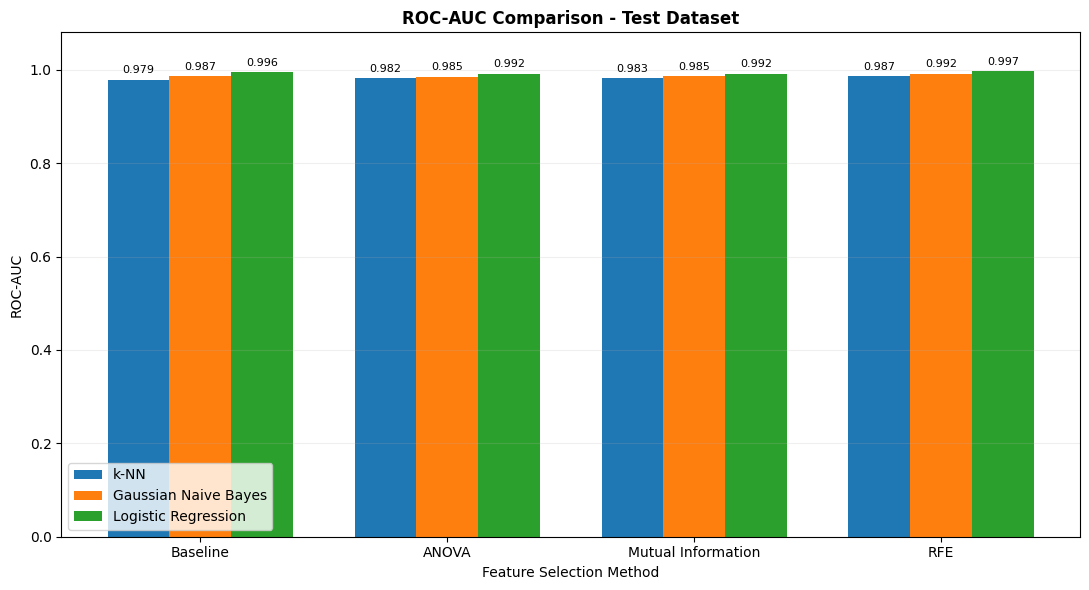

In [14]:

import matplotlib.pyplot as plt
import numpy as np

methods = [
    "Baseline",
    "ANOVA",
    "Mutual Information",
    "RFE"
]

algorithms = [
    "k-NN",
    "Gaussian Naive Bayes",
    "Logistic Regression"
]

metrics = {
    "Accuracy": "Accuracy",
    "F1-Score": "F1",
    "ROC-AUC": "ROC_AUC"
}

x = np.arange(len(methods))
width = 0.25

for metric_title, metric_column in metrics.items():

    plt.figure(figsize=(11, 6))

    for i, algorithm in enumerate(algorithms):

        values = [
            test_df[
                (test_df["Ozellik_Secimi"] == method) &
                (test_df["Algoritma"] == algorithm)
            ][metric_column].iloc[0]
            for method in methods
        ]

        bars = plt.bar(
            x + (i - 1) * width,
            values,
            width,
            label=algorithm
        )

        plt.bar_label(
            bars,
            fmt="%.3f",
            padding=3,
            fontsize=8
        )

    plt.xticks(x, methods)
    plt.ylim(0, 1.08)
    plt.ylabel(metric_title)
    plt.xlabel("Feature Selection Method")

    plt.title(
        f"{metric_title} Comparison - Test Dataset",
        fontweight="bold"
    )

    plt.legend()
    plt.grid(axis="y", alpha=0.2)
    plt.tight_layout()

    filename = metric_title.replace("-", "_").lower()
    plt.savefig(
        f"{filename}_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


In [15]:

# Makalede kullanılacak sonuçları kaydet

final_cv_df.to_excel(
    "capraz_dogrulama_sonuclari.xlsx",
    index=False
)

test_df.to_excel(
    "test_sonuclari.xlsx",
    index=False
)

features_df.to_excel(
    "secilen_ozellikler.xlsx",
    index=False
)

print("Dosyalar başarıyla oluşturuldu!")
print("1. capraz_dogrulama_sonuclari.xlsx")
print("2. test_sonuclari.xlsx")
print("3. secilen_ozellikler.xlsx")


Dosyalar başarıyla oluşturuldu!
1. capraz_dogrulama_sonuclari.xlsx
2. test_sonuclari.xlsx
3. secilen_ozellikler.xlsx
